# Fast Food Marketing Campaign: A/B/C Test Analysis

**Which of three marketing promotions sells the most of a new menu item?**

A fast-food chain tested three promotions for a new menu item across **137 locations** for **four weeks**. This notebook estimates how each promotion affects sales and checks whether that effect depends on market size. It uses a **two-way ANOVA**, **Tukey's HSD** post-hoc test and **bootstrap confidence intervals**.

> **Dataset:** [Fast Food Marketing Campaign A/B Test](https://www.kaggle.com/datasets/chebotinaa/fast-food-marketing-campaign-ab-test) (Kaggle) &nbsp;|&nbsp; **Tools:** Python · pandas · statsmodels · pingouin · seaborn

---

## 📑 Table of Contents

| # | Section | Description |
|:-:|:--|:--|
| 1 | 🎯 [Project Goal & Target Metric](#goal) | Business context, target metric and hypotheses |
| 2 | ⚙️ [Setup](#setup) | Libraries used in the analysis |
| 3 | 📥 [Data Loading & Validation](#data) | Loading the dataset and checking the experimental design |
| 4 | 🔍 [Exploratory Analysis](#eda) | Sales distribution by promotion and market size |
| 5 | 🧹 [Data Preparation](#prep) | Aggregating sales by location and checking group sizes |
| 6 | 📊 [Two-Way ANOVA](#anova) | Effects of promotion, market size and their interaction |
| 7 | 🔬 [Post-hoc Analysis: Tukey HSD](#tukey) | Pairwise comparisons and 95% confidence intervals |
| 8 | 🔁 [Bootstrap Confidence Intervals](#bootstrap) | Non-parametric check of the Tukey intervals |
| 9 | ✅ [Conclusions & Recommendation](#conclusions) | Key findings and business decision |

---

<a id="goal"></a>
## 1. Project Goal & Target Metric

### Business context
A fast-food chain plans to add a new item to its menu and has three candidate marketing campaigns to promote it: **Promotion 1**, **Promotion 2** and **Promotion 3**. To find out which one has the greatest effect on sales, the chain launched the new item in locations across several randomly selected markets. Each location received **one promotion**, and the chain recorded the item's weekly sales for the **first four weeks**.

### Goal
Determine whether the three promotions lead to different sales and, if so, which promotion(s) the company should roll out.

### Target metric
**`SalesInThousands`**: weekly sales of the new item per location, in thousands. The campaigns exist to sell the new item, so sales measure each promotion's success directly. For the statistical tests, the metric is summarized as **average weekly sales per location** over the four-week test (see [Data Preparation](#prep)).

### Hypotheses (α = 0.05)
- **H₀:** Mean sales are equal across the three promotions.
- **H₁:** At least one promotion has a different mean sales.

The locations belong to markets of different sizes (Small, Medium, Large). So the analysis also checks whether **market size** affects sales and whether it changes the effect of the promotions.

<a id="setup"></a>
## 2. Setup

The analysis uses `kagglehub` to download the data, `pandas` and `numpy` for data handling, `matplotlib` and `seaborn` for visualization, and `statsmodels` and `pingouin` for the statistical tests.

In [1]:
import kagglehub
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pingouin as pg
import numpy as np

<a id="data"></a>
## 3. Data Loading & Validation

The dataset is downloaded directly from Kaggle. Following the dataset documentation, no additional cleaning is required: there are no missing values and every feature has the appropriate data type.

Each row is one week of sales at one location.

In [2]:
path = kagglehub.dataset_download("chebotinaa/fast-food-marketing-campaign-ab-test")
marketing_campaigns = pd.read_csv(os.path.join(path,"WA_Marketing-Campaign.csv"))

marketing_campaigns.sample(5)

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
193,4,Small,308,28,2,2,58.01
226,5,Medium,407,6,3,3,37.84
205,5,Medium,402,25,2,2,50.28
184,4,Small,306,13,1,1,53.79
308,6,Medium,513,7,1,1,44.98


Before the analysis, it's important to confirm that the data matches the experimental design. Every location should have **four weeks** of data, a **single promotion** and the **same market size** throughout the test.

In [3]:
chk = marketing_campaigns.groupby("LocationID").agg(n_weeks=('week','nunique'),
                                                    n_promos=('Promotion','nunique'),
                                                    n_markets=('MarketSize','nunique'))
chk.describe()

,n_weeks,n_promos,n_markets
count,137.0,137.0,137.0
mean,4.0,1.0,1.0
std,0.0,0.0,0.0
min,4.0,1.0,1.0
25%,4.0,1.0,1.0
50%,4.0,1.0,1.0
75%,4.0,1.0,1.0
max,4.0,1.0,1.0


✔️ All **137 locations** have exactly four weeks of data, one promotion and a consistent market size, so the dataset matches the experimental design.

<a id="eda"></a>
## 4. Exploratory Analysis

`Promotion` is a label that identifies a campaign, so it is treated as a **categorical** variable rather than a number. The boxplots below show weekly sales by promotion (left) and by promotion and market size (right).

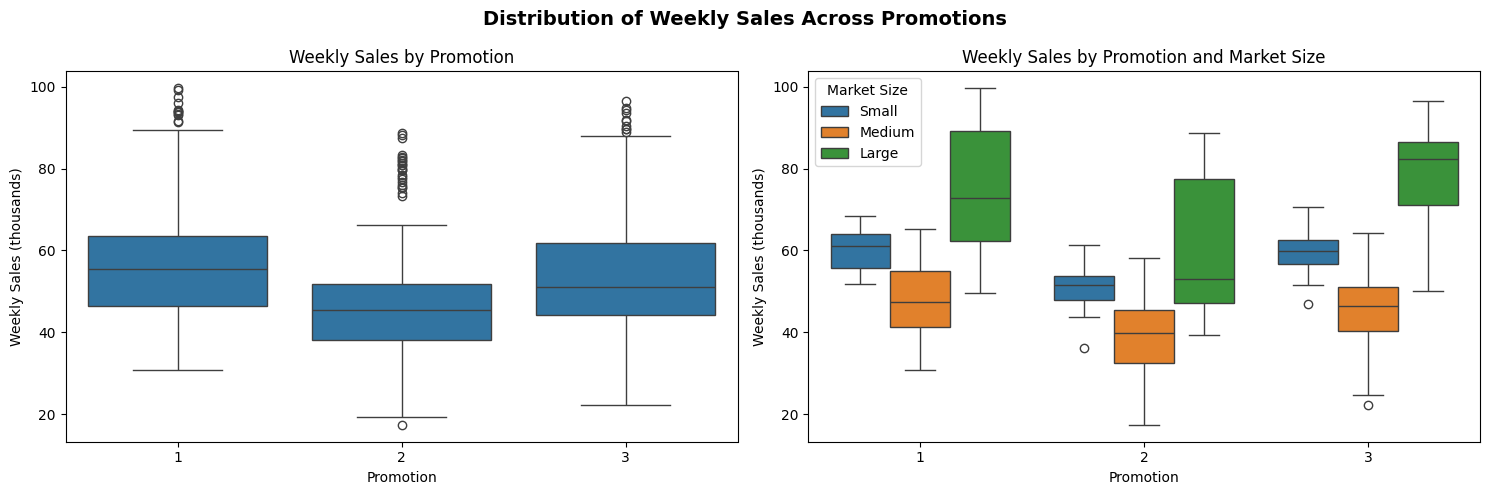

In [4]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
sns.boxplot(data=marketing_campaigns, x="Promotion", y="SalesInThousands", ax=ax[0])
ax[0].set_title("Weekly Sales by Promotion")
ax[0].set_xlabel("Promotion")
ax[0].set_ylabel("Weekly Sales (thousands)")
sns.boxplot(data=marketing_campaigns, x="Promotion", y="SalesInThousands", hue="MarketSize",
            hue_order=["Small", "Medium", "Large"], ax=ax[1])
ax[1].set_title("Weekly Sales by Promotion and Market Size")
ax[1].set_xlabel("Promotion")
ax[1].set_ylabel("Weekly Sales (thousands)")
ax[1].legend(title="Market Size")
fig.suptitle("Distribution of Weekly Sales Across Promotions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Observations**
- **By promotion (left):** Promotion 2 shows lower sales than Promotions 1 and 3, which look similar to each other. This leads to the central question of the analysis: *is there a real difference between the three promotions, and how large is it?*
- **By promotion and market size (right):** Splitting the same boxplots by market size shows that sales levels differ between market sizes and that the distributions overlap within each promotion. This suggests that market size, also a categorical feature, may influence sales, so it is included in the analysis.

<a id="prep"></a>
## 5. Data Preparation

The objective is defined and the dataset's consistency is confirmed, so the next step is to aggregate the data to **one row per location**. Each row holds the location's **mean weekly sales** over the four weeks, along with its promotion and market size.

In [5]:
store = marketing_campaigns.groupby(['LocationID','Promotion','MarketSize'], as_index=False)['SalesInThousands'].mean()
store.Promotion = store.Promotion.astype('category')

The table below counts the locations for each promotion within each market size. These group sizes help interpret the statistical results later. Note that **Small markets have only 4–6 locations per promotion**.

In [6]:
pd.crosstab(store.MarketSize,store.Promotion)

Promotion,1,2,3
MarketSize,,,
Large,14,16,12
Medium,24,27,29
Small,5,4,6


<a id="anova"></a>
## 6. Two-Way ANOVA

### Why ANOVA?
A two-way ANOVA is the model that best fits this experiment because it:
- Compares the means of **more than two groups** in a single test.
- Avoids the inflated **Type I error** rate that comes from running multiple t-tests.
- Analyzes **multiple factors** at once, which matters here because market size may also affect sales.
- Quantifies which **factors and groups** contribute most to the differences in means.
- Can be followed by a **post-hoc test** that identifies which groups differ.

The model includes promotion, market size and their interaction: `SalesInThousands ~ C(Promotion) * C(MarketSize)`.

In [7]:
model = smf.ols('SalesInThousands ~ C(Promotion) * C(MarketSize)', data=store).fit()
anova = sm.stats.anova_lm(model, typ=2)
print(anova)

                                  sum_sq     df          F        PR(>F)
C(Promotion)                 3244.817690    2.0  16.191861  5.384924e-07
C(MarketSize)               19450.760385    2.0  97.060618  2.229458e-26
C(Promotion):C(MarketSize)    529.184907    4.0   1.320334  2.658987e-01
Residual                    12825.476387  128.0        NaN           NaN


### Results

| Factor | F | p-value | Significant at α = 0.05? |
|:--|--:|--:|:-:|
| Promotion | 16.19 | 5.38e-07 | ✔️ Yes |
| Market size | 97.06 | 2.23e-26 | ✔️ Yes |
| Promotion × Market size | 1.32 | 0.266 | ✖️ No |

1. **Promotion affects sales.** The p-value is far below 0.05, so H₀ is rejected: at least one promotion has different mean sales.
2. **Market size is the main driver of sales.** Its F statistic is much larger than the one for promotion, so market size moves sales even more than the choice of promotion.
3. **No interaction.** There is no evidence that market size changes the effect of the promotions.

The interaction plot below makes the last point easier to see: the pattern across promotions is similar in all three market sizes.

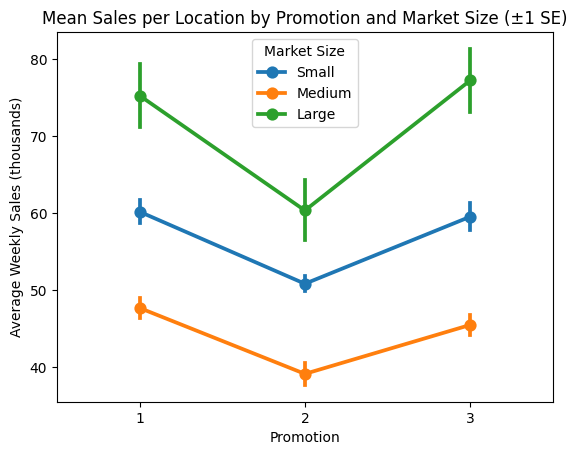

In [8]:
ax = sns.pointplot(data=store, x='Promotion', y='SalesInThousands',
                   hue='MarketSize', hue_order=['Small', 'Medium', 'Large'], errorbar='se')
ax.set_title("Mean Sales per Location by Promotion and Market Size (±1 SE)")
ax.set_xlabel("Promotion")
ax.set_ylabel("Average Weekly Sales (thousands)")
ax.legend(title="Market Size")
plt.show()

<a id="tukey"></a>
## 7. Post-hoc Analysis: Tukey HSD

The ANOVA confirms that the promotions differ, but not *which* ones. **Tukey's HSD** test compares every pair of promotions while controlling the family-wise error rate. It is run separately for each market size.

In [9]:
for mk, g in store.groupby('MarketSize'):
    print(mk)
    print(pg.pairwise_tukey(data=g, dv='SalesInThousands', between='Promotion').round(3))

Large
   A  B  mean_A  mean_B    diff     se      T  p_tukey  hedges
0  1  2  75.236  60.322  14.914  5.511  2.706    0.027   0.942
1  1  3  75.236  77.204  -1.968  5.924 -0.332    0.941  -0.129
2  2  3  60.322  77.204 -16.882  5.751 -2.936    0.015  -1.093
Medium
   A  B  mean_A  mean_B   diff     se      T  p_tukey  hedges
0  1  2  47.673  39.114  8.558  1.979  4.324    0.000   1.192
1  1  3  47.673  45.469  2.204  1.947  1.132    0.498   0.317
2  2  3  39.114  45.469 -6.355  1.887 -3.368    0.003  -0.866
Small
   A  B  mean_A  mean_B   diff     se      T  p_tukey  hedges
0  1  2  60.162  50.811  9.352  2.360  3.963    0.005   2.942
1  1  3  60.162  59.514  0.648  2.130  0.304    0.950   0.152
2  2  3  50.811  59.514 -8.704  2.271 -3.833    0.006  -2.179


The pattern is the same in all three market sizes:
- **Promotion 2 performs significantly worse** than Promotions 1 and 3 (p < 0.05).
- There is **no evidence of a difference between Promotions 1 and 3** (p > 0.05).

This confirms what the exploratory analysis suggested at the start.

### Confidence intervals
A p-value shows *whether* a difference exists, not *how large* it is. The `pairwise_tukeyhsd` function provides the **95% confidence intervals** for each pairwise difference.

In [10]:
for mk, g in store.groupby('MarketSize'):
    print(mk)
    res = pairwise_tukeyhsd(g['SalesInThousands'], g['Promotion'], alpha=0.05)
    print(res.summary())

Large


 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2 -14.9139 0.0266 -28.3403 -1.4874   True
     1      3   1.9681 0.9411 -12.4649 16.4011  False
     2      3  16.8819  0.015   2.8715 30.8924   True
-----------------------------------------------------
Medium


 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2  -8.5583 0.0001 -13.2886 -3.8279   True
     1      3  -2.2037 0.4975  -6.8567  2.4492  False
     2      3   6.3545 0.0034   1.8452 10.8638   True
-----------------------------------------------------
Small


 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2  -9.3519 0.0049 -15.6472 -3.0565   True
     1      3  -0.6483 0.9504   -6.331  5.0343  False
     2      3   8.7035 0.0062   2.6458 14.7612   True
-----------------------------------------------------


Focusing on how much **Promotions 1 and 3 outperform Promotion 2** (average weekly sales per location, in thousands):

| Market size | Promotion 1 vs 2 | Promotion 3 vs 2 |
|:--|:-:|:-:|
| Large | 1.49 to 28.34 | 2.87 to 30.89 |
| Medium | 3.83 to 13.29 | 1.85 to 10.86 |
| Small | 3.06 to 15.65 | 2.65 to 14.76 |

None of these intervals includes zero, which is consistent with the significant differences found above.

<a id="bootstrap"></a>
## 8. Bootstrap Confidence Intervals

To check the results, the intervals are recomputed with a **bootstrap** (10,000 resamples per group). Each market involves three comparisons, so the significance level is adjusted from 0.05 to **0.05/3** (Bonferroni). This makes the adjusted intervals (`ICadj`) comparable to the Tukey intervals. The unadjusted 95% intervals (`IC95`) are shown for reference.

In [11]:
rng = np.random.default_rng(42)
B = 10000
pairs = [(1, 2), (1, 3), (2, 3)]

rows = []
for mk, g in store.groupby('MarketSize'):
    data = {p: g.loc[g['Promotion'] == p, 'SalesInThousands'].to_numpy()
            for p in [1, 2, 3]}

    boot_means = {}
    for p, v in data.items():
        idx = rng.integers(0, len(v), size=(B, len(v)))
        boot_means[p] = v[idx].mean(axis=1)

    for a, b in pairs:
        obs = data[b].mean() - data[a].mean()
        diffs = boot_means[b] - boot_means[a]
        lo95, hi95 = np.percentile(diffs, [2.5, 97.5])
        loB, hiB = np.percentile(diffs, [0.833, 99.167])
        rows.append({'MarketSize': mk, 'comparison': f'{b} vs {a}',
                     'n_a': len(data[a]), 'n_b': len(data[b]),
                     'difference': obs,
                     'IC95_lower': lo95, 'IC95_upper': hi95,
                     'ICadj_lower': loB, 'ICadj_upper': hiB})

res = pd.DataFrame(rows).round(2)
print(res.to_string(index=False))

MarketSize comparison  n_a  n_b  difference  IC95_lower  IC95_upper  ICadj_lower  ICadj_upper
     Large     2 vs 1   14   16      -14.91      -25.22       -4.11       -27.33        -1.71
     Large     3 vs 1   14   12        1.97       -9.03       12.31       -11.74        14.43
     Large     3 vs 2   16   12       16.88        5.63       26.89         3.21        28.65
    Medium     2 vs 1   24   27       -8.56      -12.33       -4.78       -13.20        -4.04
    Medium     3 vs 1   24   29       -2.20       -5.89        1.39        -6.61         2.23
    Medium     3 vs 2   27   29        6.35        2.55       10.17         1.87        10.94
     Small     2 vs 1    5    4       -9.35      -12.67       -6.55       -13.41        -6.15
     Small     3 vs 1    5    6       -0.65       -5.05        3.17        -6.12         3.80
     Small     3 vs 2    4    6        8.70        4.94       12.03         4.13        12.65


Adjusted bootstrap intervals for how much **Promotions 1 and 3 outperform Promotion 2** (in thousands):

| Market size | Promotion 1 vs 2 | Promotion 3 vs 2 |
|:--|:-:|:-:|
| Large | 1.71 to 27.33 | 3.21 to 28.65 |
| Medium | 4.04 to 13.20 | 1.87 to 10.94 |
| Small | 6.15 to 13.41 | 4.13 to 12.65 |

### Tukey vs. bootstrap
- The bootstrap leads to the **same conclusions** as Tukey's HSD: Promotion 2 is worse than Promotions 1 and 3, and Promotions 1 and 3 do not differ.
- The bootstrap intervals are **narrower**. In larger groups, such as the Medium markets, the two methods give almost the same intervals.
- The smaller the group, the bigger the gap between the methods. In the **Small markets**, the bootstrap intervals are about 3.5k–5.5k narrower than the Tukey intervals.

<a id="conclusions"></a>
## 9. Conclusions & Recommendation

### Key findings
1. **The data is reliable.** All 137 locations have four weeks of data, a single promotion and a consistent market size, and no cleaning was required.
2. **The promotion affects sales.** The two-way ANOVA finds a significant difference between promotions (F = 16.19, p < 0.001).
3. **Market size is the strongest driver of sales** (F = 97.06, p < 0.001). It has a bigger effect than the promotion itself.
4. **The promotion effect is consistent across markets.** The interaction between promotion and market size is not significant (F = 1.32, p = 0.266).
5. **Promotion 2 is the weakest campaign.** In every market size, it sells significantly less than Promotions 1 and 3 (Tukey HSD, p < 0.05), and none of the confidence intervals for the difference includes zero.
6. **Promotions 1 and 3 perform alike.** There is no statistically significant difference between them in any market size.
7. **The bootstrap confirms the Tukey results.** It reaches the same conclusions with narrower intervals, especially in the Small markets, where groups are smallest.

### Recommendation
- ✖️ **Discard Promotion 2.** It consistently underperforms the other two campaigns, regardless of market size.
- ✔️ **Roll out Promotion 1 or Promotion 3.** The data does not show that either one outperforms the other, so the choice between them can rest on other business criteria, such as campaign cost.

### Limitations
- The Small markets have only 4–6 locations per promotion, so their estimates are less precise and should be read with caution.